# 01: Baseline CNN on clean MNIST

Train a small CNN on clean MNIST and record its test accuracy. This is the reference point for the poisoning experiments in notebook 02, where a successful backdoor should leave clean accuracy roughly unchanged.

## 1. Imports and device

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device :", device)
if device == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device : cuda
GPU    : NVIDIA GeForce RTX 4080


## 2. Seed and paths

A fixed seed keeps runs comparable between the clean and poisoned settings. Paths are relative to the project root, one level above `notebooks/`.

In [2]:
SEED = 42
torch.manual_seed(SEED)

ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Data dir   :", DATA_DIR)
print("Results dir:", RESULTS_DIR)

Data dir   : /home/saad/dev/ml-backdoor-security-lab/data
Results dir: /home/saad/dev/ml-backdoor-security-lab/results


## 3. Load MNIST

`ToTensor()` gives each image as a `[1, 28, 28]` tensor with pixel values in [0, 1]. No normalization is applied, so a trigger can be written later as a plain pixel value of 1.0 (white).

In [3]:
transform = transforms.ToTensor()

train_set = datasets.MNIST(root=DATA_DIR, train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=transform)

print("Train images:", len(train_set))
print("Test images :", len(test_set))

100.0%
100.0%
100.0%
100.0%

Train images: 60000
Test images : 10000


## 4. Inspect samples

Image shape: torch.Size([1, 28, 28])
Pixel range: 0.0 to 1.0
Label      : 5


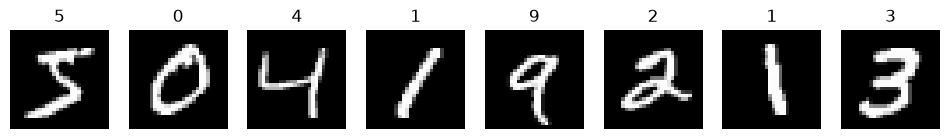

In [4]:
import matplotlib.pyplot as plt

img, label = train_set[0]
print("Image shape:", img.shape)          # torch.Size([1, 28, 28])
print("Pixel range:", img.min().item(), "to", img.max().item())
print("Label      :", label)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    x, y = train_set[i]
    ax.imshow(x.squeeze(), cmap="gray")
    ax.set_title(y)
    ax.axis("off")
plt.show()

## 5. Data loaders

Batch size 128 for training (shuffled), 1000 for testing.

In [5]:
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=1000,       shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print("Batch images:", images.shape)   # [128, 1, 28, 28]
print("Batch labels:", labels.shape)   # [128]

Batch images: torch.Size([128, 1, 28, 28])
Batch labels: torch.Size([128])


## 6. Model

Two conv + max-pool blocks followed by two fully connected layers (about 422k parameters).

Shapes: `[1,28,28]` → conv1 → `[32,28,28]` → pool → `[32,14,14]` → conv2 → `[64,14,14]` → pool → `[64,7,7]` → flatten (3136) → 128 → 10 logits.

In [6]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)          # keep batch dim, flatten the rest
        x = F.relu(self.fc1(x))
        return self.fc2(x)               # raw scores (logits), no softmax here

model = SmallCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Trainable parameters:", n_params)

SmallCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 421642


## 7. Training and evaluation

Adam (lr = 1e-3) with cross-entropy loss. `evaluate` returns the fraction of test samples classified correctly.

In [7]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        preds = model(x).argmax(dim=1)   # index of the highest score = predicted digit
        correct += (preds == y).sum().item()
    return correct / len(loader.dataset)

## 8. Train for 5 epochs

In [8]:
EPOCHS = 5

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch}: train loss {train_loss:.4f} | clean test accuracy {test_acc:.2%}")

Epoch 1: train loss 0.2482 | clean test accuracy 98.00%
Epoch 2: train loss 0.0586 | clean test accuracy 98.61%
Epoch 3: train loss 0.0397 | clean test accuracy 98.79%
Epoch 4: train loss 0.0306 | clean test accuracy 99.04%
Epoch 5: train loss 0.0244 | clean test accuracy 98.89%


## 9. Save weights and metrics

In [9]:
clean_acc = evaluate(model, test_loader)
torch.save(model.state_dict(), RESULTS_DIR / "baseline_cnn.pt")

with open(RESULTS_DIR / "baseline_metrics.txt", "w") as f:
    f.write(f"clean_accuracy={clean_acc:.4f}\n")

print(f"Baseline clean accuracy: {clean_acc:.2%}")
print("Saved to:", RESULTS_DIR / "baseline_cnn.pt")

Baseline clean accuracy: 98.89%
Saved to: /home/saad/dev/ml-backdoor-security-lab/results/baseline_cnn.pt


## Result

Clean test accuracy after 5 epochs: **98.89%** (RTX 4080, seed 42).

Accuracy moved between 98.6% and 99.0% over epochs 2 to 5, so the model has essentially converged. Differences of a few tenths of a percent between runs should not be read as meaningful.

Next: `02_badnets_poisoning.ipynb`.